# Stage 4: Clock synchronisation and the coincidence window

**Question:** how precisely must the two nodes' clocks agree? This is the question White Rabbit answers in CERN's quantum network lab.

**Mechanism.** Detectors time-stamp every click. A and B decide which clicks belong to the same pair by comparing
time-stamps, accepting pairs closer than a *coincidence window* τ. Clock errors spread the true pairs over a wider time range:
* a **narrow window** then misses true pairs (lower rate);
* a **wide window** lets in more accidental coincidences (lower quality). Accidentals grow as
  $\text{singles}_A \times \text{singles}_B \times \tau$, so they grow with the *square* of source brightness.

So poor sync forces a wide window, and a wide window forces a dimmer source. That is where the cost shows up.

**Sync levels compared** (standard deviation of the clock error, illustrative):
10 ps (White Rabbit-like), 100 ps, 1 ns (PTP-like), 10 ns (loosely synchronised).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qnet import physics as P, quantum as Q, plotstyle as S
S.apply()

In [2]:
SYNCS = {"10 ps (White Rabbit-like)": 10e-12, "100 ps": 100e-12, "1 ns (PTP-like)": 1e-9, "10 ns": 10e-9}

## 1. Time-stamp simulation

A Monte Carlo time-tagger: random emission times, detection losses, detector jitter, clock error, and dark counts.
The histogram of time differences shows the true-pair peak on a flat floor of accidentals.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


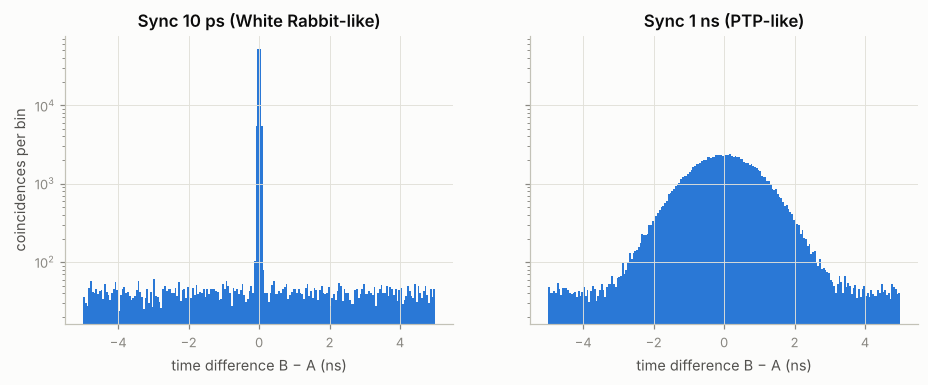

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, (lab, sj) in zip(axs, [("10 ps (White Rabbit-like)", 10e-12), ("1 ns (PTP-like)", 1e-9)]):
    mc = P.simulate_timestamps(25, 0.05, window=10e-9, sync_jitter=sj, pair_rate=1e7)
    ax.hist(mc["dt"] * 1e9, bins=200, color=S.SERIES[0], edgecolor="none")
    ax.set(xlabel="time difference B − A (ns)", title=f"Sync {lab}", yscale="log")
axs[0].set_ylabel("coincidences per bin")
S.save(fig, "04_timestamp_histograms")

In [4]:
# Check: Monte Carlo counts vs the analytic rate formulas
print(f"{'window':>8} {'true MC':>10} {'true th':>10} {'acc MC':>9} {'acc th':>9}")
for win in [100e-12, 1e-9, 5e-9]:
    mc = P.simulate_timestamps(25, 0.1, win, sync_jitter=1e-9, pair_rate=1e7, seed=7)
    an = P.link_counts(25, win, sync_jitter=1e-9, pair_rate=1e7)
    print(f"{win*1e12:6.0f}ps {mc['true']:10.0f} {an['true']:10.0f} {mc['acc']:9.0f} {an['acc']:9.0f}")

  window    true MC    true th    acc MC    acc th
   100ps      90650      91074      2230      2285


  1000ps     877050     874564     21040     22849
  5000ps    2251090    2256290     92150    114243


True coincidences agree within about 1%. For wide windows the formula predicts somewhat *more* accidentals than the
time-tagger finds, because the tagger matches each click to its nearest partner and a true partner usually wins.
So the analytic model is slightly pessimistic (conservative), which is the safe direction for a security estimate.

## 2. The window trade-off at a fixed brightness

At 25 km with a bright source ($10^7$ pairs/s): secret key rate against window width, for each sync level.
The quantum state for each point is built and measured in PennyLane.

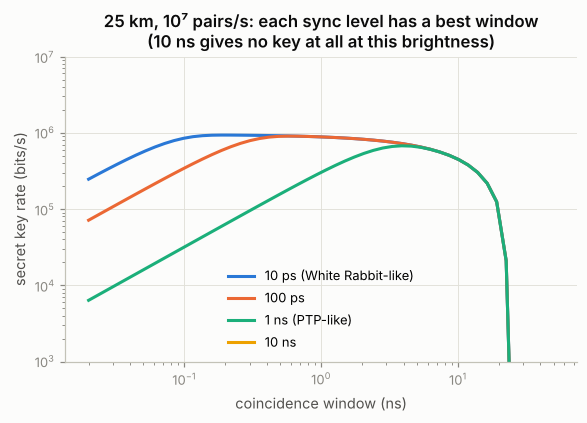

In [5]:
link_corr = Q.make_link_circuit("corr")
def key_at(L_km, win, sj, **kw):
    w, c = P.link_werner_weight(L_km, win, sj, **kw)
    xx, yy, zz = link_corr(float(w))                  # PennyLane state -> measured correlations
    qz, qx = Q.qber(float(xx), float(zz))
    return Q.key_rate(c["true"] + c["acc"], qz, qx), qz

wins = np.logspace(np.log10(20e-12), np.log10(50e-9), 50)
fig, ax = plt.subplots(figsize=(6, 3.6))
for lab, sj in SYNCS.items():
    k = [key_at(25, win, sj, pair_rate=1e7)[0] for win in wins]
    ax.loglog(wins * 1e9, np.maximum(k, 1), label=lab)
ax.set(xlabel="coincidence window (ns)", ylabel="secret key rate (bits/s)",
       title="25 km, 10⁷ pairs/s: each sync level has a best window\n(10 ns gives no key at all at this brightness)", ylim=(1e3, 1e7))
ax.legend(loc="lower center")
S.save(fig, "04_window_tradeoff")

## 3. Headline result: optimised key rate against distance

For each sync level and distance, choose the best window *and* the best source brightness
(capped at $2\times10^7$ pairs/s, roughly where detectors saturate). Better sync lets you run the source brighter.

10 ps (White Rabbit-like)  at 25 km:  1.84e+06 bits/s  (best brightness 2e+07 pairs/s,   1.0x below 10 ps)
100 ps                     at 25 km:  1.74e+06 bits/s  (best brightness 2e+07 pairs/s,   1.1x below 10 ps)
1 ns (PTP-like)            at 25 km:  1.01e+06 bits/s  (best brightness 2e+07 pairs/s,   1.8x below 10 ps)
10 ns                      at 25 km:  1.14e+05 bits/s  (best brightness 3.2e+06 pairs/s,  16.2x below 10 ps)


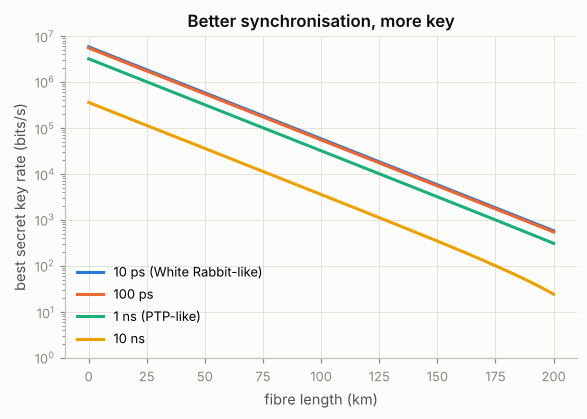

In [6]:
from scipy.optimize import minimize
R_grid = np.logspace(4, np.log10(2e7), 30)
def best_key(L_km, sj):
    sig = P.total_jitter(sj); best = (0, None, None)
    for R in R_grid:
        for kfac in np.linspace(0.5, 6, 23):
            w, c = P.link_werner_weight(L_km, kfac * sig, sj, pair_rate=R)
            kr = Q.key_rate(c["true"] + c["acc"], (1 - w) / 2, (1 - w) / 2)   # analytic (checked above)
            if kr > best[0]: best = (kr, R, kfac * sig)
    return best

L = np.linspace(0, 200, 41)
fig, ax = plt.subplots(figsize=(6, 3.8))
table = {}
for lab, sj in SYNCS.items():
    res = [best_key(Lk, sj) for Lk in L]
    kr = np.array([r[0] for r in res])
    ax.semilogy(L, np.maximum(kr, 1e-1), label=lab)
    table[lab] = (np.interp(25, L, kr), res[L.tolist().index(25)][1])
ax.set(xlabel="fibre length (km)", ylabel="best secret key rate (bits/s)",
       title="Better synchronisation, more key", ylim=(1, 1e7))
ax.legend(loc="lower left")
S.save(fig, "04_key_vs_distance_sync")
ref = table["10 ps (White Rabbit-like)"][0]
for lab, (k, R) in table.items():
    print(f"{lab:26s} at 25 km: {k:9.3g} bits/s  (best brightness {R:.2g} pairs/s, {ref/k:5.1f}x below 10 ps)")

## 4. An uncorrected clock offset

A *constant* offset between clocks (for example, an uncalibrated fibre delay) shifts the coincidence peak sideways.
A narrow window then misses it completely. A wide window tolerates the offset, but lets in more accidentals (section 2).
So low jitter only pays off if the offset is also calibrated to a similar precision. White Rabbit does both:
it measures the link delay and corrects for it.

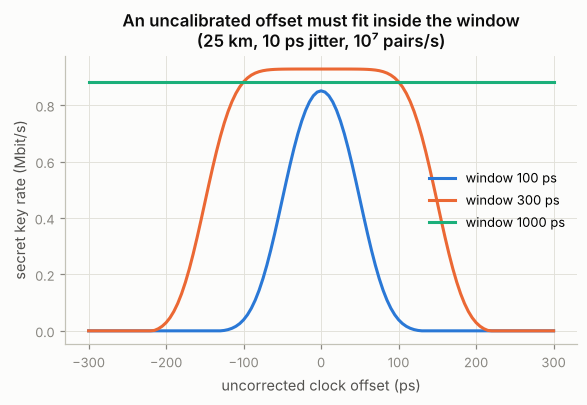

In [7]:
offs = np.linspace(-300e-12, 300e-12, 121)
fig, ax = plt.subplots(figsize=(6, 3.4))
for i, win in enumerate([100e-12, 300e-12, 1e-9]):
    k = [Q.key_rate(*(lambda w, c: (c["true"] + c["acc"], (1 - w) / 2, (1 - w) / 2))(
            *P.link_werner_weight(25, win, 10e-12, offset=o, pair_rate=1e7))) for o in offs]
    ax.plot(offs * 1e12, np.array(k) / 1e6, label=f"window {win*1e12:.0f} ps")
ax.set(xlabel="uncorrected clock offset (ps)", ylabel="secret key rate (Mbit/s)", title="An uncalibrated offset must fit inside the window\n(25 km, 10 ps jitter, 10⁷ pairs/s)")
ax.legend()
S.save(fig, "04_clock_offset")

## 5. Sharing the fibre with a classical channel

If the timing signal (or data) travels in the same fibre as the quantum photons, some of its light scatters
(mainly Raman scattering) into the quantum channel as background counts at B. We sweep this background rate.
Maximum distance with positive key, per sync level:

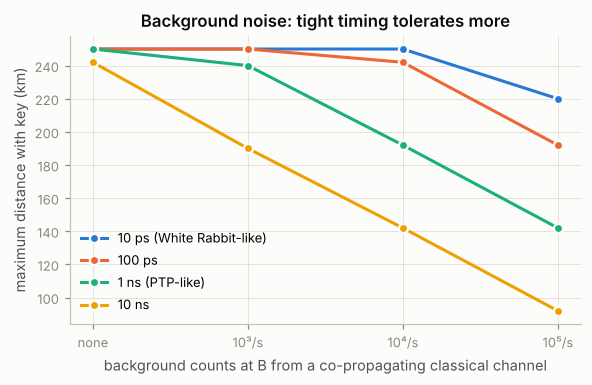

In [8]:
noise = [0, 1e3, 1e4, 1e5]
Lfine = np.linspace(0, 250, 126)
fig, ax = plt.subplots(figsize=(6, 3.4))
for lab, sj in SYNCS.items():
    dmax = []
    for nb in noise:
        sig = P.total_jitter(sj); reach = 0
        for Lk in Lfine:
            ok = False
            for R in R_grid[::3]:
                for kfac in [1, 2, 3, 4]:
                    w, c = P.link_werner_weight(Lk, kfac * sig, sj, pair_rate=R, extra_noise_B=nb)
                    if Q.bbm92_key_fraction((1 - w) / 2, (1 - w) / 2) > 0: ok = True; break
                if ok: break
            if ok: reach = Lk
        dmax.append(reach)
    ax.plot(range(len(noise)), dmax, "-o", label=lab, mec="#fcfcfb", mew=1.5)
ax.set(xticks=range(len(noise)), xticklabels=["none", "10³/s", "10⁴/s", "10⁵/s"],
       xlabel="background counts at B from a co-propagating classical channel",
       ylabel="maximum distance with key (km)", title="Background noise: tight timing tolerates more")
ax.legend(loc="lower left")
S.save(fig, "04_coprop_noise")

## Takeaways

* The Monte Carlo time-tagger agrees with the analytic coincidence formulas.
* Synchronisation quality sets how bright the source can run. In this model, at 25 km a 10 ns sync gives
  roughly an order of magnitude less key than 10 ps (White Rabbit-like), and 1 ns gives about half.
* An uncalibrated constant offset of ~100 ps removes almost all the key in a 100 ps window. Low jitter is only useful together with offset calibration.
* At a fixed high brightness (10⁷ pairs/s), a 10 ns sync gives no secure key at any window width.
* With background light from a classical channel sharing the fibre, tight timing gives most of the reach back. This connects to the co-propagation tests in CERN's lab.